Train Random Forest classifiers with extensive hyperparameter optimization, feature selection, and out-of-bag (OOB) error estimation to improve predictive performance and generalizability.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 600

In [4]:
age = np.random.normal(55, 12, n_samples).clip(20, 85)
bmi = np.random.normal(28, 5, n_samples).clip(15, 45)
blood_pressure = np.random.normal(130, 18, n_samples).clip(90, 190)
glucose = np.random.normal(110, 30, n_samples).clip(70, 250)
cholesterol = np.random.normal(200, 35, n_samples).clip(120, 320)

In [5]:
random_noise_1 = np.random.normal(0, 1, n_samples)
random_noise_2 = np.random.uniform(0, 100, n_samples)

In [6]:
risk_logits = (
    0.04 * (age - 55)
    + 0.1 * (bmi - 28)
    + 0.05 * (glucose - 110)
    + 0.003 * (bmi - 28) * (glucose - 110)
    - 0.02 * (cholesterol - 200)
)
probs = 1 / (1 + np.exp(-risk_logits))
target = (probs > np.median(probs)).astype(int)

In [7]:
df_rf = pd.DataFrame({
    'age': age.round(1),
    'bmi': bmi.round(1),
    'blood_pressure': blood_pressure.round(1),
    'glucose': glucose.round(1),
    'cholesterol': cholesterol.round(1),
    'noise_feature_1': random_noise_1.round(3),
    'noise_feature_2': random_noise_2.round(2),
    'high_risk': target
})

In [8]:
print("Dataset Shape:", df_rf.shape)
print("Target Class Distribution:\n", df_rf['high_risk'].value_counts())

Dataset Shape: (600, 8)
Target Class Distribution:
 high_risk
1    300
0    300
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

In [10]:
X = df_rf.drop(columns=['high_risk'])
y = df_rf['high_risk']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [12]:
rf_oob = RandomForestClassifier(
    n_estimators=200,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_oob.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, n_jobs=-1, oob_score=True,
                       random_state=42)

In [13]:
print(f"OOB Accuracy Estimate : {rf_oob.oob_score_:.4f}")
print(f"Test Set Accuracy Score: {accuracy_score(y_test, rf_oob.predict(X_test)):.4f}")
print(f"Test Set F1-Score      : {f1_score(y_test, rf_oob.predict(X_test)):.4f}")

OOB Accuracy Estimate : 0.9089
Test Set Accuracy Score: 0.8800
Test Set F1-Score      : 0.8767


In [14]:
from sklearn.model_selection import GridSearchCV

In [15]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

In [16]:
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(oob_score=True, random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

In [17]:
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

In [18]:
print("Best Parameters:", rf_grid.best_params_)
print(f"Best 5-Fold CV F1-Score: {rf_grid.best_score_:.4f}")
print(f"Tuned Model OOB Score  : {best_rf.oob_score_:.4f}")

Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best 5-Fold CV F1-Score: 0.9097
Tuned Model OOB Score  : 0.9000


In [19]:
import matplotlib.pyplot as plt

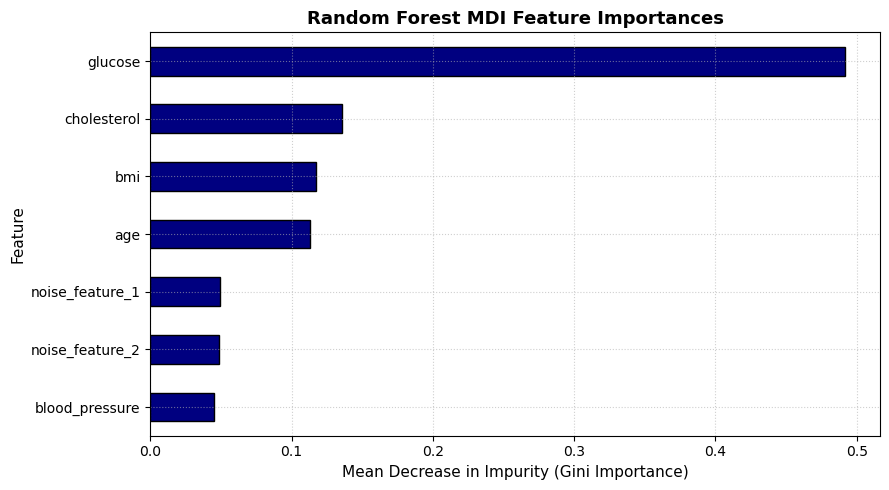

In [21]:
feature_importances = pd.Series(
    best_rf.feature_importances_, 
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
feature_importances.plot(kind='barh', color='navy', edgecolor='black')

plt.title("Random Forest MDI Feature Importances", fontsize=13, fontweight='bold')
plt.xlabel("Mean Decrease in Impurity (Gini Importance)", fontsize=11)
plt.ylabel("Feature", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [22]:
selected_features = feature_importances[feature_importances > 0.05].index.tolist()
print("\nSelected Predictive Features:", selected_features)



Selected Predictive Features: ['age', 'bmi', 'cholesterol', 'glucose']


In [23]:
X_train_sub = X_train[selected_features]
X_test_sub = X_test[selected_features]

In [24]:
refined_rf = RandomForestClassifier(
    **rf_grid.best_params_,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

In [25]:
refined_rf.fit(X_train_sub, y_train)

RandomForestClassifier(min_samples_leaf=2, n_jobs=-1, oob_score=True,
                       random_state=42)

In [26]:
y_pred_sub = refined_rf.predict(X_test_sub)

In [27]:
print(f"Refined Test Accuracy : {accuracy_score(y_test, y_pred_sub):.4f}")
print(f"Refined Test F1-Score : {f1_score(y_test, y_pred_sub):.4f}")
print(f"Refined OOB Score     : {refined_rf.oob_score_:.4f}")

Refined Test Accuracy : 0.9000
Refined Test F1-Score : 0.9007
Refined OOB Score     : 0.9156
